# 02 - Exploratory Data Analysis

**Input:** `data/processed/shipments_full.csv` (from `01_data_preparation.ipynb`)
**Goal:** understand the target and the four drivers, and settle the modelling decisions that depend on the data.
No model is trained here.

Decisions this notebook settles:
1. Is the 60-day cap on `transit_days` reasonable?
2. Does the target need a transform?
3. Which features carry signal, and are any of them redundant?
4. Is there drift over time that should shape the train/test split?

In [1]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

def ensure(dest, label):
    """Make sure `dest` exists. In Colab, ask for an upload when it is missing."""
    dest = Path(dest)
    if dest.exists():
        return dest
    if IN_COLAB:
        from google.colab import files

        print(f"Please upload: {label}")
        dest.parent.mkdir(parents=True, exist_ok=True)
        for name, content in files.upload().items():
            (dest.parent / name).write_bytes(content)
    assert dest.exists(), f"{dest} not found. Run the earlier step first or upload {label}."
    return dest

path = ensure(ROOT / "data" / "processed" / "shipments_full.csv", "shipments_full.csv")
df = pd.read_csv(path, parse_dates=["dispatch_date"])
print(df.shape)
df.head()

(94701, 8)


,order_id,seller_id,dispatch_date,weight_kg,distance_km,warehouse_load,carrier_tier,transit_days
0,36989eb07a0de2d3d3129eea35553875,939f6e231201f26803cb5c3a3d2940b3,2016-10-08,3.0,1043.442839,1,Economy,3.000000
1,7033745709b7cf1bac7d2533663592de,df560393f3a51e74553ab94004ba5c87,2016-10-08,1.2,988.068591,1,Economy,3.000000
2,cd3b8574c82b42fc8129f6d502690c3e,b499c00f28f4b7069ff6550af8c1348a,2016-10-08,9.0,194.572193,1,Economy,6.231933
3,51725d3e4bdfc97e28b40543310da8a3,ecccfa2bb93b34a3bf033cc5d1dcdc69,2016-10-09,2.3,141.789607,2,Standard,16.843623
4,bcbc0973414b1dd97555e6f8e9713cfa,cca3071e3e9bb7d12640c9fbe2301306,2016-10-09,5.0,459.146273,1,Economy,7.288981


## 1. Overview

In [2]:
print(df.dtypes, "\n")
print("nulls:", int(df.isna().sum().sum()))
df[["weight_kg", "distance_km", "warehouse_load", "transit_days"]].describe(percentiles=[.5, .9, .99]).round(2)

order_id                  object
seller_id                 object
dispatch_date     datetime64[ns]
weight_kg                float64
distance_km              float64
warehouse_load             int64
carrier_tier              object
transit_days             float64
dtype: object 

nulls: 0


,weight_kg,distance_km,warehouse_load,transit_days
count,94701.00,94701.00,94701.00,94701.00
mean,2.36,601.02,3.58,9.35
std,4.73,593.55,4.65,8.79
min,0.00,0.00,1.00,-5.74
50%,0.73,433.90,2.00,7.11
90%,6.55,1458.96,8.00,18.94
99%,22.35,2483.40,21.00,41.02
max,184.40,3398.49,63.00,205.19


## 2. The target: `transit_days`

`shipments_full.csv` still contains the rows the preparation notebook filters out (zero or negative durations, long tail).
We look at them here to check that the 60-day cap is sensible.

rows with transit_days <= 0: 12
rows above 30 days:  2662  (2.81%)
rows above 45 days:   633  (0.67%)
rows above 60 days:   223  (0.24%)
rows above 90 days:    71  (0.07%)

skewness raw  : 4.56
skewness log1p: -0.03


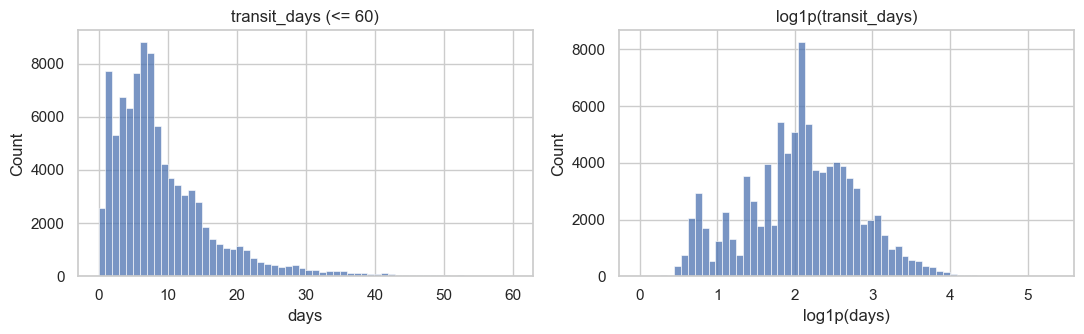

In [3]:
t = df["transit_days"]
print("rows with transit_days <= 0:", int((t <= 0).sum()))
for cap in (30, 45, 60, 90):
    print(f"rows above {cap:>2} days: {(t > cap).sum():>5}  ({(t > cap).mean() * 100:.2f}%)")

d = df[df["transit_days"] > 0].copy()
print("\nskewness raw  :", round(d["transit_days"].skew(), 2))
print("skewness log1p:", round(np.log1p(d["transit_days"]).skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(d.loc[d["transit_days"] <= 60, "transit_days"], bins=60, ax=ax[0])
ax[0].set(title="transit_days (<= 60)", xlabel="days")
sns.histplot(np.log1p(d["transit_days"]), bins=60, ax=ax[1])
ax[1].set(title="log1p(transit_days)", xlabel="log1p(days)")
plt.tight_layout()

**Findings**
- The raw target is strongly right-skewed (skewness about 4.6). After `log1p` it is almost symmetric (about 0).
  Models will be trained on `log1p(transit_days)` and their output converted back to days.
- Only about 0.24% of rows exceed 60 days, so the cap removes very little and protects the model from lost-parcel style outliers. The cap stays at 60.

## 3. Distance

               shipments  median    p90
distance_band                          
(0, 100]           17652    2.08   6.93
(100, 300]         13137    5.68  13.03
(300, 600]         30958    7.15  17.03
(600, 1000]        17609    9.10  20.11
(1000, 1500]        6448   11.83  23.20
(1500, 2500]        7777   14.05  28.76
(2500, 4000]         862   17.02  32.04


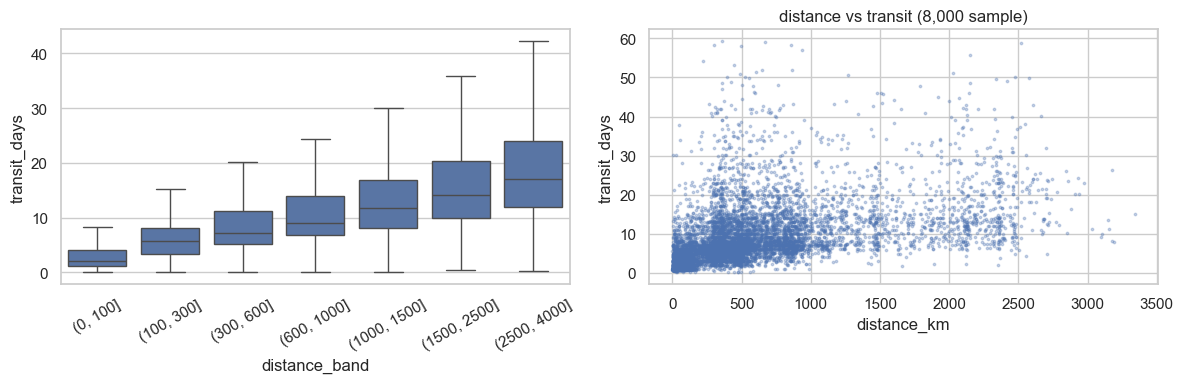

In [4]:
d = d[d["transit_days"] <= 60].copy()
d["distance_band"] = pd.cut(d["distance_km"], [0, 100, 300, 600, 1000, 1500, 2500, 4000])

print(d.groupby("distance_band", observed=True)["transit_days"]
        .agg(shipments="size", median="median", p90=lambda s: s.quantile(.9)).round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=d, x="distance_band", y="transit_days", showfliers=False, ax=ax[0])
ax[0].tick_params(axis="x", rotation=30)
sample = d.sample(8000, random_state=0)
ax[1].scatter(sample["distance_km"], sample["transit_days"], s=3, alpha=.3)
ax[1].set(xlabel="distance_km", ylabel="transit_days", title="distance vs transit (8,000 sample)")
plt.tight_layout()

**Finding:** distance is the main driver. The median rises from about 2 days under 100 km to about 17 days beyond 2,500 km.
The spread (p90) widens with distance too, so uncertainty is larger for long routes, which is why intervals matter.

## 4. Weight

In [5]:
d["weight_band"] = pd.cut(d["weight_kg"], [0, .3, .6, 1, 2, 5, 10, 200])
print(d.groupby("weight_band", observed=True)["transit_days"].agg(shipments="size", median="median").round(2))
print("\nSpearman(weight, transit):", round(d["weight_kg"].corr(d["transit_days"], method="spearman"), 3))

               shipments  median
weight_band                     
(0.0, 0.3]         25009    6.84
(0.3, 0.6]         18691    7.09
(0.6, 1.0]         11298    7.15
(1.0, 2.0]         16002    7.23
(2.0, 5.0]         10905    7.19
(5.0, 10.0]         7495    7.41
(10.0, 200.0]       5066    7.20

Spearman(weight, transit): 0.063


**Finding:** weight has almost no effect on transit time on its own (medians between 6.8 and 7.4 days across weight bands).
Olist's carrier network ships by route, not by parcel weight. Weight is kept as a feature because the brief asks for it,
but the model should be expected to lean on it very little.

## 5. Warehouse load

In [6]:
d["load_band"] = pd.cut(d["warehouse_load"], [0, 1, 2, 4, 8, 16, 100])
print(d.groupby("load_band", observed=True)["transit_days"].agg(shipments="size", median="median").round(2))
print("\nSpearman(load, transit):", round(d["warehouse_load"].corr(d["transit_days"], method="spearman"), 3))

           shipments  median
load_band                   
(0, 1]         37359    7.02
(1, 2]         18757    7.06
(2, 4]         17254    7.09
(4, 8]         12465    7.25
(8, 16]         6480    7.78
(16, 100]       2151    7.95

Spearman(load, transit): 0.041


**Finding:** a very weak but monotone effect: busier sellers have slightly longer transit (median about 7.0 days at load 1 versus about 8.0 at load 16 or more).
Warehouse load is derived from the data, and 39% of shipments have a load of 1, so its signal is small.

## 6. Carrier tier (proxy)

              weight_kg  distance_km  transit_days
carrier_tier                                      
Economy            2.60       693.15          9.16
Express            0.25       116.78          4.27
Standard           0.60       486.60          7.70

median transit at 300-600 km: {'Economy': 7.24, 'Express': 7.03, 'Standard': 7.16}


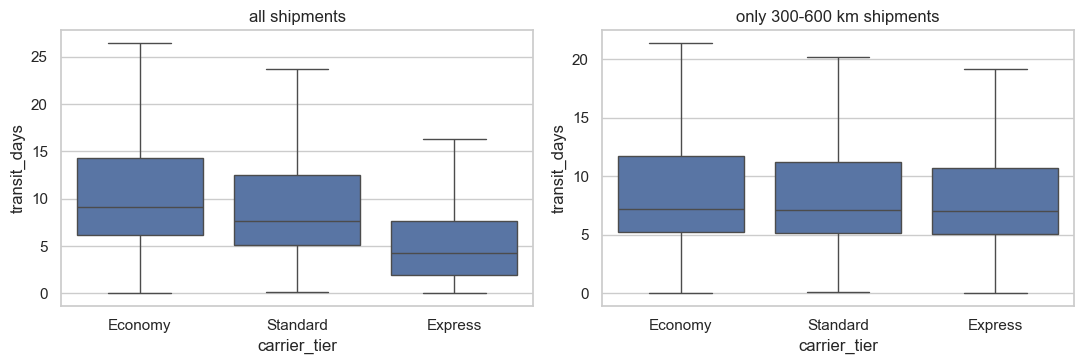

In [7]:
print(d.groupby("carrier_tier")[["weight_kg", "distance_km", "transit_days"]].median().round(2))

order = ["Economy", "Standard", "Express"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.boxplot(data=d, x="carrier_tier", y="transit_days", order=order, showfliers=False, ax=ax[0])
ax[0].set_title("all shipments")
mid = d[(d["distance_km"] > 300) & (d["distance_km"] <= 600)]
sns.boxplot(data=mid, x="carrier_tier", y="transit_days", order=order, showfliers=False, ax=ax[1])
ax[1].set_title("only 300-600 km shipments")
plt.tight_layout()

print("\nmedian transit at 300-600 km:", mid.groupby("carrier_tier")["transit_days"].median().round(2).to_dict())

**Finding - important caveat:** across all shipments Express looks about twice as fast as Economy.
But the tier is built from freight price per kg per km, so Express simply means "short distance and light parcel".
When distance is held fixed (300-600 km) the three tiers have almost the same median transit time (about 7.0 to 7.2 days).
The tier is a **proxy for the route**, not an independent service level, so the model will mostly use distance and the tier adds little beyond it.
This must be stated in the README.

## 7. Day of week and time drift

     shipments  median
Mon      19146    7.15
Tue      21061    7.13
Wed      19192    7.00
Thu      16661    7.02
Fri      16633    7.14
Sat       1737    9.42
Sun         36    3.91

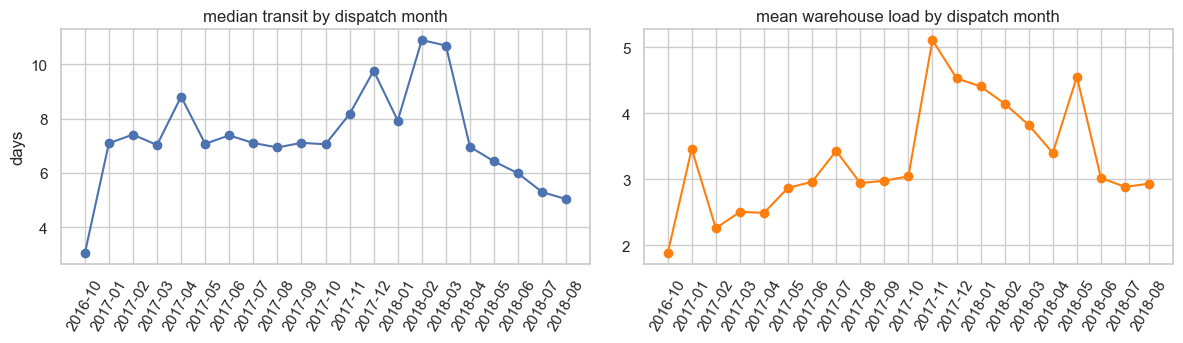

In [8]:
dow = d.groupby(d["dispatch_date"].dt.dayofweek)["transit_days"].agg(shipments="size", median="median").round(2)
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print(dow)

monthly = d.groupby(d["dispatch_date"].dt.to_period("M")).agg(
    shipments=("order_id", "size"), median=("transit_days", "median"), mean_load=("warehouse_load", "mean")
)
monthly = monthly[monthly["shipments"] >= 200]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(monthly.index.astype(str), monthly["median"], marker="o")
ax[0].set(title="median transit by dispatch month", ylabel="days")
ax[0].tick_params(axis="x", rotation=60)
ax[1].plot(monthly.index.astype(str), monthly["mean_load"], marker="o", color="tab:orange")
ax[1].set(title="mean warehouse load by dispatch month")
ax[1].tick_params(axis="x", rotation=60)
plt.tight_layout()

**Findings**
- Saturday and Sunday dispatches behave differently from weekdays (Saturday slower at about 9.4 days, Sunday quicker at about 3.9 days, but Sunday has very few shipments),
  so day of week is worth including.
- The target **drifts over time**: monthly medians (months with at least 200 shipments) range from about 5 to 11 days,
  peak between December 2017 and March 2018, and fall to about 5 days by mid-2018.
  Warehouse load also changes over the period (monthly mean from about 2 to 5) as the marketplace grew.
  A random train/test split would hide this. **The split must be chronological**, with the test set being the most recent period.
  Performance on the test set will be a realistic, and somewhat pessimistic, view of future behaviour.

## 8. Correlations

tier             -0.385
warehouse_load    0.041
weight_kg         0.063
distance_km       0.618
transit_days      1.000
Name: transit_days, dtype: float64

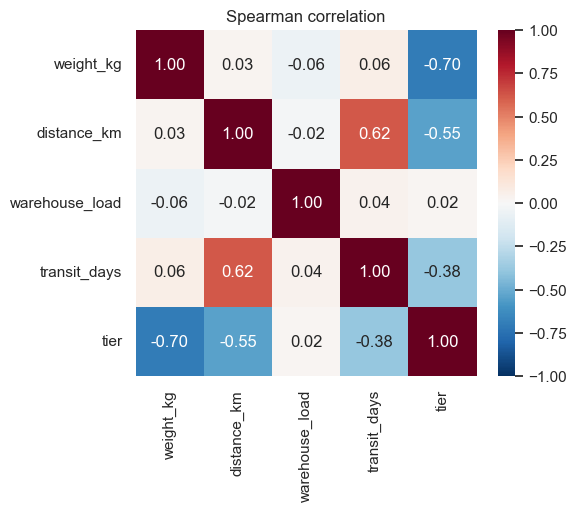

In [9]:
num = d[["weight_kg", "distance_km", "warehouse_load", "transit_days"]].copy()
num["tier"] = d["carrier_tier"].map({"Economy": 0, "Standard": 1, "Express": 2})
corr = num.corr(method="spearman")
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Spearman correlation")
corr["transit_days"].round(3).sort_values()

**Findings:** distance dominates (about 0.62 with the target). Weight (about 0.06) and load (about 0.04) are weak.
`tier` is strongly related to weight (about -0.70) and distance (about -0.55), which confirms it is derived from them.

## 9. Conclusions carried into modelling

| Decision | Choice | Reason |
|---|---|---|
| Transit cap | keep 60 days | affects only about 0.24% of rows |
| Target transform | train on `log1p(transit_days)`, report in days | skewness 4.6 becomes about 0 |
| Distance, weight | use `log1p` | both are heavily skewed, effects are multiplicative |
| Extra features | day of week of dispatch (month is tested in the modelling notebook) | weekend effect; month has under 2 years of history |
| Split | chronological: train, validation, calibration, test | the target drifts over time |
| Metric | MAE in days (primary), RMSE and R2 secondary | readable by dispatchers |
| Expectation | distance drives the model; weight, load and tier add little | measured above |
| Intervals | must widen for long routes | spread grows with distance |